In [219]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

### 1. Load All Datasets

In [220]:
student_info = pd.read_csv("studentInfo.csv", na_values='?')
student_info.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


In [221]:
student_registration = pd.read_csv("studentRegistration.csv", na_values='?')
student_registration.head()

,code_module,code_presentation,id_student,date_registration,date_unregistration
0,AAA,2013J,11391,-159.0,NaN
1,AAA,2013J,28400,-53.0,NaN
2,AAA,2013J,30268,-92.0,12.0
3,AAA,2013J,31604,-52.0,NaN
4,AAA,2013J,32885,-176.0,NaN


In [222]:
assessments = pd.read_csv("assessments.csv", na_values='?')
assessments.head()

,code_module,code_presentation,id_assessment,assessment_type,date,weight
0,AAA,2013J,1752,TMA,19.0,10.0
1,AAA,2013J,1753,TMA,54.0,20.0
2,AAA,2013J,1754,TMA,117.0,20.0
3,AAA,2013J,1755,TMA,166.0,20.0
4,AAA,2013J,1756,TMA,215.0,30.0


In [223]:
student_assessment = pd.read_csv("studentAssessment.csv", na_values='?')
student_assessment.head()

,id_assessment,id_student,date_submitted,is_banked,score
0,1752,11391,18,0,78.0
1,1752,28400,22,0,70.0
2,1752,31604,17,0,72.0
3,1752,32885,26,0,69.0
4,1752,38053,19,0,79.0


In [224]:
student_vle = pd.read_csv( "studentVle.csv", na_values='?',
usecols=["code_module", "code_presentation", "id_student", "id_site", "date", "sum_click"])
print(student_vle.shape)
student_vle.head()

(10655280, 6)


,code_module,code_presentation,id_student,id_site,date,sum_click
0,AAA,2013J,28400,546652,-10,4
1,AAA,2013J,28400,546652,-10,1
2,AAA,2013J,28400,546652,-10,1
3,AAA,2013J,28400,546614,-10,11
4,AAA,2013J,28400,546714,-10,1


In [225]:
courses = pd.read_csv("courses.csv", na_values='?')
courses.head()

,code_module,code_presentation,module_presentation_length
0,AAA,2013J,268
1,AAA,2014J,269
2,BBB,2013J,268
3,BBB,2014J,262
4,BBB,2013B,240


In [226]:
vle = pd.read_csv("vle.csv", na_values='?')
vle.head()

,id_site,code_module,code_presentation,activity_type,week_from,week_to
0,546943,AAA,2013J,resource,NaN,NaN
1,546712,AAA,2013J,oucontent,NaN,NaN
2,546998,AAA,2013J,resource,NaN,NaN
3,546888,AAA,2013J,url,NaN,NaN
4,547035,AAA,2013J,resource,NaN,NaN


In [227]:
CUTOFF_DAY = 90
KEY = ["code_module","code_presentation","id_student"]

### 2. Target Column
   - 1 : Fail or Withdrawn
   - 0 : Pass or Distinction

In [228]:
student_info.columns.tolist()

['code_module',
 'code_presentation',
 'id_student',
 'gender',
 'region',
 'highest_education',
 'imd_band',
 'age_band',
 'num_of_prev_attempts',
 'studied_credits',
 'disability',
 'final_result']

In [229]:
student_info["final_result"].value_counts()

final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64

In [230]:
student_info["at_risk"] = 0
student_info.loc[student_info["final_result"] == "Fail", "at_risk"] = 1
student_info.loc[student_info["final_result"] == "Withdrawn", "at_risk"] = 1

In [231]:
student_info["at_risk"].value_counts()

at_risk
1    17208
0    15385
Name: count, dtype: int64

### 3. Merging Datasets

In [232]:
print("Student_info:",student_info.shape)
print("student_registration:",student_registration.shape)
print("Assessments:",assessments.shape)
print("student_assessment:",student_assessment.shape)
print("student_Vle:",student_vle.shape)

Student_info: (32593, 13)
student_registration: (32593, 5)
Assessments: (206, 6)
student_assessment: (173912, 5)
student_Vle: (10655280, 6)


 - Merge Student_info and Student_registration

In [233]:
student_level_base = student_info.merge(student_registration, on=KEY, how="left")
print(student_level_base.shape)
student_level_base.head()

(32593, 15)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,at_risk,date_registration,date_unregistration
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,0,-159.0,NaN
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,0,-53.0,NaN
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn,1,-92.0,12.0
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,0,-52.0,NaN
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,0,-176.0,NaN


- Remove students who already left before day 90

In [234]:
print("Students before:", len(student_level_base))

Students before: 32593


In [235]:
still_studying = student_level_base["date_unregistration"].isna() | (student_level_base["date_unregistration"] > CUTOFF_DAY)
student_level_base = student_level_base[still_studying]
print("Students after :", len(student_level_base))
student_level_base.sample(5)

Students after : 25562


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,at_risk,date_registration,date_unregistration
13990,DDD,2013B,549795,F,South West Region,A Level or Equivalent,10-20,0-35,0,60,N,Pass,0,-48.0,NaN
10703,CCC,2014J,201425,M,South East Region,A Level or Equivalent,60-70%,0-35,0,60,N,Pass,0,-115.0,NaN
21266,EEE,2014J,483858,F,Scotland,A Level or Equivalent,70-80%,0-35,0,60,N,Pass,0,-123.0,NaN
23978,FFF,2013J,124379,F,Wales,A Level or Equivalent,40-50%,0-35,1,90,N,Fail,1,-22.0,NaN
25384,FFF,2013J,591940,M,London Region,Lower Than A Level,50-60%,35-55,0,60,N,Pass,0,-86.0,NaN


- Student_Assessments and Assessments

In [236]:
student_assessment.sample(5)

,id_assessment,id_student,date_submitted,is_banked,score
95069,25368,657245,243,0,51.0
169522,37433,634320,215,0,80.0
79026,25350,561881,87,0,100.0
107620,34863,1974271,130,0,81.0
151915,34905,681073,52,0,76.0


In [237]:
assessments.sample(5)

,code_module,code_presentation,id_assessment,assessment_type,date,weight
72,CCC,2014J,24299,Exam,NaN,100.0
28,BBB,2013J,15007,CMA,208.0,1.0
80,DDD,2013B,25347,CMA,206.0,6.0
7,AAA,2014J,1759,TMA,54.0,20.0
164,FFF,2014J,34905,CMA,241.0,0.0


In [238]:
sa = student_assessment.merge(assessments, on="id_assessment", how="left")
sa.sample(5)

,id_assessment,id_student,date_submitted,is_banked,score,code_module,code_presentation,assessment_type,date,weight
10784,14992,248103,95,0,80.0,BBB,2013B,CMA,89.0,1.0
141777,34896,2674773,163,0,88.0,FFF,2014B,CMA,227.0,0.0
73494,25344,530748,117,0,43.0,DDD,2013B,CMA,114.0,4.0
122730,34877,568234,172,0,70.0,FFF,2013J,TMA,173.0,25.0
159456,37415,541252,58,0,85.0,GGG,2013J,TMA,61.0,0.0


In [239]:
sa.shape

(173912, 10)

- Keep only work submitted **up to day 90**.  
- Remove rows with no score.

In [240]:
sa = sa[sa["date_submitted"] <= CUTOFF_DAY]
sa = sa.dropna(subset=["score"])
sa.shape

(70991, 10)

In [241]:
sa.head()

,id_assessment,id_student,date_submitted,is_banked,score,code_module,code_presentation,assessment_type,date,weight
0,1752,11391,18,0,78.0,AAA,2013J,TMA,19.0,10.0
1,1752,28400,22,0,70.0,AAA,2013J,TMA,19.0,10.0
2,1752,31604,17,0,72.0,AAA,2013J,TMA,19.0,10.0
3,1752,32885,26,0,69.0,AAA,2013J,TMA,19.0,10.0
4,1752,38053,19,0,79.0,AAA,2013J,TMA,19.0,10.0


- "late" Column made, which shows 1 when date_submitted>date.


In [242]:
sa["late"] = 0
sa.loc[sa["date_submitted"] > sa["date"], "late"] = 1

- "wieghted_score" = score × weight ÷ 100 

In [243]:
sa["weighted_score"] = (sa["score"] * sa["weight"]) / 100
sa.sample(5)

,id_assessment,id_student,date_submitted,is_banked,score,code_module,code_presentation,assessment_type,date,weight,late,weighted_score
89039,25362,603303,20,0,75.0,DDD,2014J,TMA,20.0,5.0,0,3.75
70792,25341,487711,25,0,100.0,DDD,2013B,CMA,23.0,2.0,1,2.00
4043,14984,541013,19,0,62.0,BBB,2013B,TMA,19.0,5.0,0,3.10
145796,34900,1532711,51,0,90.0,FFF,2014J,TMA,52.0,12.5,0,11.25
3390,14984,262741,19,0,84.0,BBB,2013B,TMA,19.0,5.0,0,4.20


- "num_assessments_done" column create by adding same "id_assessments".

In [244]:
num_assessments_done = sa.groupby(KEY)["id_assessment"].count().reset_index()
num_assessments_done = num_assessments_done.rename(columns={"id_assessment": "num_assessments_done"})
num_assessments_done.sample(5)

,code_module,code_presentation,id_student,num_assessments_done
1519,BBB,2013B,543926,3
23215,FFF,2014J,682894,3
6421,BBB,2014J,691312,2
25417,GGG,2014J,651210,1
1582,BBB,2013B,547620,4


- "avg_score" of a student in all the assessments.

In [245]:
avg_score = sa.groupby(KEY)["score"].mean().reset_index()
avg_score = avg_score.rename(columns={"score": "avg_score"})
avg_score.sample(5)

,code_module,code_presentation,id_student,avg_score
14858,DDD,2014J,690298,65.00
21221,FFF,2014B,612982,67.25
17882,FFF,2013B,498636,65.00
5700,BBB,2014J,636953,1.00
12705,DDD,2013J,2581822,73.50


- "min_score" of every student.

In [246]:
min_score = sa.groupby(KEY)["score"].min().reset_index()
min_score = min_score.rename(columns={"score": "min_score"})
min_score.sample(5)

,code_module,code_presentation,id_student,min_score
22669,FFF,2014J,644210,70.0
23074,FFF,2014J,677206,62.0
12006,DDD,2013J,568963,78.0
16183,EEE,2014B,611999,65.0
19106,FFF,2013J,438644,58.0


- "weighted_score" by adding all assessments weighted score.

In [247]:
weighted_score = sa.groupby(KEY)["weighted_score"].sum().reset_index()
weighted_score.head()

,code_module,code_presentation,id_student,weighted_score
0,AAA,2013J,11391,24.8
1,AAA,2013J,28400,20.6
2,AAA,2013J,31604,21.4
3,AAA,2013J,32885,12.9
4,AAA,2013J,38053,21.7


- "late_submissions" submit late summation.

In [248]:
late_submissions = sa.groupby(KEY)["late"].sum().reset_index()
late_submissions = late_submissions.rename(columns={"late": "late_submissions"})
late_submissions.head()

,code_module,code_presentation,id_student,late_submissions
0,AAA,2013J,11391,0
1,AAA,2013J,28400,1
2,AAA,2013J,31604,0
3,AAA,2013J,32885,2
4,AAA,2013J,38053,1


- Keep only clicks up to day 90.

In [249]:
student_vle = student_vle[student_vle["date"] <= CUTOFF_DAY]
print(student_vle.shape)
student_vle.sample(5)

(5486878, 6)


,code_module,code_presentation,id_student,id_site,date,sum_click
260394,AAA,2014J,2358969,877135,79,1
4812331,DDD,2014J,590886,813710,8,3
6769495,FFF,2013B,166421,527230,88,2
7571074,FFF,2013J,598498,716216,37,1
2026356,CCC,2014B,131933,729789,18,1


- "total_clicks" by adding all click per students.

In [250]:
total_clicks = student_vle.groupby(KEY)["sum_click"].sum().reset_index()
total_clicks = total_clicks.rename(columns={"sum_click": "total_clicks"})
total_clicks.sample(5)

,code_module,code_presentation,id_student,total_clicks
12827,DDD,2013J,380429,318
19010,EEE,2014J,634094,251
12300,DDD,2013B,559282,830
2756,BBB,2013J,512775,180
2034,BBB,2013B,558654,55


- "active_days" 

In [251]:
active_days = student_vle.groupby(KEY)["date"].nunique().reset_index()
active_days = active_days.rename(columns={"date": "active_days"})
active_days.head()

,code_module,code_presentation,id_student,active_days
0,AAA,2013J,11391,23
1,AAA,2013J,28400,36
2,AAA,2013J,30268,12
3,AAA,2013J,31604,51
4,AAA,2013J,32885,35


- "resources_visited"

In [252]:
resources_visited = student_vle.groupby(KEY)["id_site"].nunique().reset_index()
resources_visited = resources_visited.rename(columns={"id_site": "resources_visited"})
resources_visited.head()

,code_module,code_presentation,id_student,resources_visited
0,AAA,2013J,11391,37
1,AAA,2013J,28400,46
2,AAA,2013J,30268,22
3,AAA,2013J,31604,46
4,AAA,2013J,32885,43


In [253]:
recent_vle = student_vle[student_vle["date"] > CUTOFF_DAY - 30]
clicks_last_30_days = recent_vle.groupby(KEY)["sum_click"].sum().reset_index()
clicks_last_30_days = clicks_last_30_days.rename(columns={"sum_click": "clicks_last_30_days"})
clicks_last_30_days.sample(5)

,code_module,code_presentation,id_student,clicks_last_30_days
7682,CCC,2014J,633328,57
3031,BBB,2013J,2174835,35
17880,FFF,2014B,293454,74
6443,CCC,2014B,631925,23
8208,CCC,2014J,1942870,232


### 5. Join All Features.

In [254]:
data = student_level_base.copy()

In [255]:
data = data.merge(num_assessments_done, on=KEY, how="left")
data = data.merge(avg_score, on=KEY, how="left")
data = data.merge(min_score, on=KEY, how="left")
data = data.merge(weighted_score, on=KEY, how="left")
data = data.merge(late_submissions, on=KEY, how="left")
data = data.merge(total_clicks, on=KEY, how="left")
data = data.merge(active_days, on=KEY, how="left")
data = data.merge(resources_visited, on=KEY, how="left")
data = data.merge(clicks_last_30_days, on=KEY, how="left")

In [256]:
data.columns.tolist()

['code_module',
 'code_presentation',
 'id_student',
 'gender',
 'region',
 'highest_education',
 'imd_band',
 'age_band',
 'num_of_prev_attempts',
 'studied_credits',
 'disability',
 'final_result',
 'at_risk',
 'date_registration',
 'date_unregistration',
 'num_assessments_done',
 'avg_score',
 'min_score',
 'weighted_score',
 'late_submissions',
 'total_clicks',
 'active_days',
 'resources_visited',
 'clicks_last_30_days']

In [257]:
print(data.shape)
data.sample(5)

(25562, 24)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,date_unregistration,num_assessments_done,avg_score,min_score,weighted_score,late_submissions,total_clicks,active_days,resources_visited,clicks_last_30_days
25095,GGG,2014J,641452,F,South Region,Lower Than A Level,20-30%,0-35,0,30,...,NaN,1.0,46.0,46.0,0.00,0.0,17.0,2.0,9.0,NaN
4178,BBB,2014B,542466,F,Scotland,A Level or Equivalent,20-30%,0-35,2,120,...,NaN,5.0,73.6,55.0,27.06,3.0,266.0,15.0,22.0,31.0
12145,DDD,2013J,608062,M,South Region,A Level or Equivalent,80-90%,0-35,0,60,...,NaN,3.0,59.0,52.0,23.40,0.0,142.0,13.0,29.0,32.0
19312,FFF,2013J,576431,M,London Region,A Level or Equivalent,60-70%,0-35,0,90,...,NaN,2.0,75.0,74.0,18.75,0.0,315.0,33.0,39.0,17.0
4199,BBB,2014B,551252,F,South West Region,A Level or Equivalent,70-80%,0-35,1,120,...,NaN,5.0,94.8,87.0,38.71,2.0,682.0,49.0,28.0,158.0


In [258]:
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 25562 entries, 0 to 25561
Data columns (total 24 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   code_module           25562 non-null  str    
 1   code_presentation     25562 non-null  str    
 2   id_student            25562 non-null  int64  
 3   gender                25562 non-null  str    
 4   region                25562 non-null  str    
 5   highest_education     25562 non-null  str    
 6   imd_band              24589 non-null  str    
 7   age_band              25562 non-null  str    
 8   num_of_prev_attempts  25562 non-null  int64  
 9   studied_credits       25562 non-null  int64  
 10  disability            25562 non-null  str    
 11  final_result          25562 non-null  str    
 12  at_risk               25562 non-null  int64  
 13  date_registration     25555 non-null  float64
 14  date_unregistration   3041 non-null   float64
 15  num_assessments_done  23836 no

In [259]:
data.duplicated().sum()

np.int64(0)

In [260]:
data.describe()

,id_student,num_of_prev_attempts,studied_credits,at_risk,date_registration,date_unregistration,num_assessments_done,avg_score,min_score,weighted_score,late_submissions,total_clicks,active_days,resources_visited,clicks_last_30_days
count,2.556200e+04,25562.000000,25562.000000,25562.000000,25555.000000,3041.000000,23836.000000,23836.000000,23836.000000,23836.000000,23836.000000,25061.000000,25061.000000,25061.000000,21744.000000
mean,7.068977e+05,0.158556,75.384164,0.398130,-65.724985,153.738902,2.854674,75.293497,65.974702,20.005772,0.743413,731.995651,33.464586,45.955548,153.844463
std,5.526390e+05,0.470331,37.377960,0.489522,47.303216,41.012068,1.316985,16.254962,20.414453,12.705868,0.990424,855.074658,23.075731,33.694623,210.999711
min,6.516000e+03,0.000000,30.000000,0.000000,-311.000000,91.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,5.058552e+05,0.000000,60.000000,0.000000,-94.000000,118.000000,2.000000,67.787500,57.000000,9.990000,0.000000,205.000000,15.000000,22.000000,34.000000
50%,5.889670e+05,0.000000,60.000000,0.000000,-52.000000,151.000000,3.000000,79.000000,70.000000,18.750000,0.000000,460.000000,29.000000,36.000000,84.000000
75%,6.409235e+05,0.000000,90.000000,1.000000,-29.000000,180.000000,3.000000,86.750000,80.000000,30.500000,1.000000,941.000000,48.000000,62.000000,185.000000
max,2.710343e+06,6.000000,630.000000,1.000000,167.000000,444.000000,12.000000,100.000000,100.000000,90.960000,6.000000,12783.000000,115.000000,313.000000,4715.000000


In [261]:
data.isnull().sum()

code_module                 0
code_presentation           0
id_student                  0
gender                      0
region                      0
highest_education           0
imd_band                  973
age_band                    0
num_of_prev_attempts        0
studied_credits             0
disability                  0
final_result                0
at_risk                     0
date_registration           7
date_unregistration     22521
num_assessments_done     1726
avg_score                1726
min_score                1726
weighted_score           1726
late_submissions         1726
total_clicks              501
active_days               501
resources_visited         501
clicks_last_30_days      3818
dtype: int64

### 6. Clean The Data

In [262]:
data[data['num_assessments_done'].isnull()]

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,date_unregistration,num_assessments_done,avg_score,min_score,weighted_score,late_submissions,total_clicks,active_days,resources_visited,clicks_last_30_days
76,AAA,2013J,195262,M,London Region,A Level or Equivalent,90-100%,0-35,0,60,...,185.0,NaN,NaN,NaN,NaN,NaN,777.0,23.0,43.0,121.0
112,AAA,2013J,281589,M,North Western Region,HE Qualification,30-40%,0-35,0,60,...,NaN,NaN,NaN,NaN,NaN,NaN,54.0,7.0,9.0,NaN
158,AAA,2013J,346843,F,Scotland,HE Qualification,50-60%,35-55,0,120,...,NaN,NaN,NaN,NaN,NaN,NaN,164.0,8.0,17.0,NaN
195,AAA,2013J,494424,F,North Region,A Level or Equivalent,80-90%,0-35,0,60,...,NaN,NaN,NaN,NaN,NaN,NaN,58.0,2.0,14.0,NaN
324,AAA,2013J,2569324,M,South Region,A Level or Equivalent,90-100%,0-35,0,120,...,93.0,NaN,NaN,NaN,NaN,NaN,26.0,3.0,4.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25529,GGG,2014J,1734156,F,Scotland,Lower Than A Level,40-50%,0-35,0,30,...,NaN,NaN,NaN,NaN,NaN,NaN,91.0,6.0,11.0,1.0
25534,GGG,2014J,1890660,F,North Region,Lower Than A Level,10-20,35-55,0,30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25536,GGG,2014J,1917808,F,West Midlands Region,A Level or Equivalent,70-80%,35-55,0,30,...,170.0,NaN,NaN,NaN,NaN,NaN,11.0,1.0,4.0,NaN
25552,GGG,2014J,2475886,F,East Anglian Region,Lower Than A Level,40-50%,35-55,0,90,...,NaN,NaN,NaN,NaN,NaN,NaN,9.0,2.0,5.0,NaN


- These Five columns have same null value and filled by 0.

In [263]:

cols1 = ['num_assessments_done','min_score','weighted_score','avg_score','late_submissions']
print(data[cols1].isnull().sum())
print(data[cols1].isnull().all(axis=1).sum())


num_assessments_done    1726
min_score               1726
weighted_score          1726
avg_score               1726
late_submissions        1726
dtype: int64
1726


In [264]:

data[cols1] = data[cols1].fillna(0)

In [265]:
data[data['total_clicks'].isnull()].sample(5)

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,date_unregistration,num_assessments_done,avg_score,min_score,weighted_score,late_submissions,total_clicks,active_days,resources_visited,clicks_last_30_days
5662,BBB,2014J,613380,F,North Region,Lower Than A Level,50-60%,0-35,0,60,...,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
16477,EEE,2014J,637292,M,Scotland,HE Qualification,20-30%,0-35,0,60,...,121.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
12627,DDD,2014B,532988,M,South West Region,A Level or Equivalent,70-80%,0-35,1,60,...,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
5210,BBB,2014J,353617,F,Wales,Lower Than A Level,0-10%,0-35,0,60,...,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
23747,GGG,2013J,594625,F,North Western Region,Lower Than A Level,30-40%,0-35,0,30,...,NaN,1.0,85.0,85.0,0.0,0.0,NaN,NaN,NaN,NaN


In [266]:
cols2 = ["total_clicks", "active_days", "resources_visited"]
print(data[cols2].isnull().sum())
print(data[cols2].isnull().all(axis=1).sum())

total_clicks         501
active_days          501
resources_visited    501
dtype: int64
501


In [267]:
data[cols2] = data[cols2].fillna(0)

In [268]:
data['clicks_last_30_days'] = data['clicks_last_30_days'].fillna(0)


In [269]:
data[data['imd_band'].isnull()]

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,date_unregistration,num_assessments_done,avg_score,min_score,weighted_score,late_submissions,total_clicks,active_days,resources_visited,clicks_last_30_days
8,AAA,2013J,53025,M,North Region,Post Graduate Qualification,NaN,55<=,0,60,...,NaN,2.0,75.5,71.0,23.1,0.0,1242.0,55.0,50.0,404.0
16,AAA,2013J,71361,M,Ireland,HE Qualification,NaN,35-55,0,60,...,NaN,2.0,84.0,82.0,25.4,0.0,1536.0,60.0,45.0,132.0
26,AAA,2013J,104476,M,Ireland,Post Graduate Qualification,NaN,35-55,0,60,...,NaN,2.0,81.5,78.0,24.1,2.0,1823.0,55.0,60.0,299.0
32,AAA,2013J,114017,F,North Region,Post Graduate Qualification,NaN,35-55,0,60,...,NaN,2.0,71.0,66.0,21.8,0.0,484.0,21.0,28.0,5.0
61,AAA,2013J,172112,M,Ireland,HE Qualification,NaN,35-55,0,60,...,NaN,2.0,63.5,60.0,19.4,1.0,507.0,41.0,39.0,105.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23668,GGG,2013J,589914,M,North Region,Lower Than A Level,NaN,0-35,0,30,...,NaN,1.0,70.0,70.0,0.0,0.0,145.0,14.0,22.0,27.0
24255,GGG,2014B,575199,F,North Western Region,Lower Than A Level,NaN,0-35,0,30,...,NaN,2.0,72.5,65.0,0.0,0.0,454.0,28.0,27.0,74.0
24462,GGG,2014B,617889,F,South West Region,Lower Than A Level,NaN,0-35,0,30,...,NaN,1.0,56.0,56.0,0.0,0.0,80.0,9.0,12.0,0.0
24829,GGG,2014B,634470,F,South Region,A Level or Equivalent,NaN,0-35,0,30,...,NaN,1.0,85.0,85.0,0.0,0.0,106.0,9.0,13.0,0.0


In [270]:
data["imd_band"] = data["imd_band"].fillna("unknown")
data["imd_band"] = data["imd_band"].str.replace("%", "", regex=False)
data["imd_band"].value_counts()

imd_band
30-40      2786
20-30      2731
10-20      2614
50-60      2504
40-50      2503
0-10       2423
70-80      2351
60-70      2342
80-90      2235
90-100     2100
unknown     973
Name: count, dtype: int64

In [271]:
data['date_registration'] = data['date_registration'].fillna(data['date_registration'].median())

In [272]:
data['has_unregistration'] = (data['date_unregistration'].notna().astype(int))
data['has_unregistration'].value_counts()

has_unregistration
0    22521
1     3041
Name: count, dtype: int64

In [273]:
data['date_unregistration'] = data['date_unregistration'].fillna(0)

In [274]:
data.isnull().sum()

code_module             0
code_presentation       0
id_student              0
gender                  0
region                  0
highest_education       0
imd_band                0
age_band                0
num_of_prev_attempts    0
studied_credits         0
disability              0
final_result            0
at_risk                 0
date_registration       0
date_unregistration     0
num_assessments_done    0
avg_score               0
min_score               0
weighted_score          0
late_submissions        0
total_clicks            0
active_days             0
resources_visited       0
clicks_last_30_days     0
has_unregistration      0
dtype: int64

- Feature Columns 


In [275]:
num_cols = data.select_dtypes(include="number").columns.tolist()
cat_cols = data.select_dtypes(include="object").columns.tolist()
print(num_cols)
print(cat_cols)

['id_student', 'num_of_prev_attempts', 'studied_credits', 'at_risk', 'date_registration', 'date_unregistration', 'num_assessments_done', 'avg_score', 'min_score', 'weighted_score', 'late_submissions', 'total_clicks', 'active_days', 'resources_visited', 'clicks_last_30_days', 'has_unregistration']
['code_module', 'code_presentation', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'disability', 'final_result']


In [276]:
num_feature_columns = ["num_assessments_done", "num_of_prev_attempts", "date_registration","date_unregistration", "studied_credits",
                       "avg_score", "min_score", "weighted_score", "late_submissions",
                       "total_clicks", "active_days", "resources_visited", "clicks_last_30_days"]

cat_feature_columns = ["code_module", "code_presentation", "gender", "region",
                       "highest_education", "imd_band", "age_band", "disability"]

- New feature: average clicks per day = (total clicks ÷ active days)

In [277]:
data["avg_clicks_per_day"] = data["total_clicks"] / data["active_days"]
data["avg_clicks_per_day"]=data["avg_clicks_per_day"].fillna(0)

In [278]:
num_feature_columns.append("avg_clicks_per_day")
print(num_feature_columns)

['num_assessments_done', 'num_of_prev_attempts', 'date_registration', 'date_unregistration', 'studied_credits', 'avg_score', 'min_score', 'weighted_score', 'late_submissions', 'total_clicks', 'active_days', 'resources_visited', 'clicks_last_30_days', 'avg_clicks_per_day']


### 7. EDA

<Axes: xlabel='at_risk', ylabel='Count'>

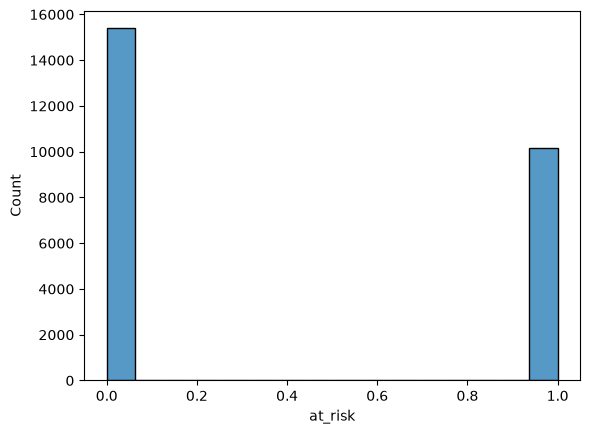

In [279]:
sns.histplot(data['at_risk'])

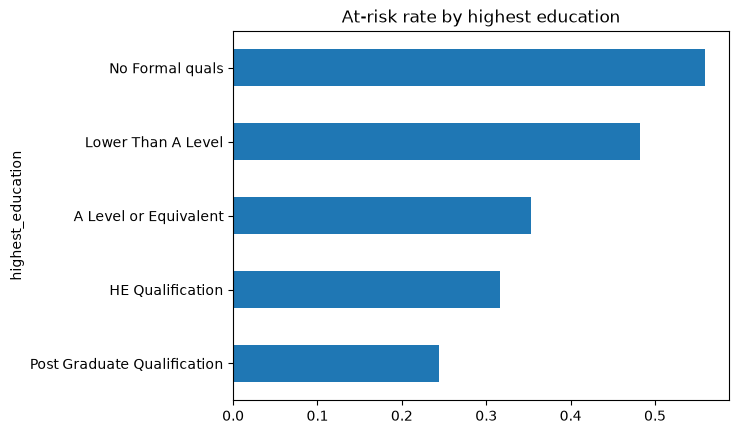

In [280]:
data.groupby("highest_education")["at_risk"].mean().sort_values().plot(kind="barh")
plt.title("At-risk rate by highest education")
plt.show()

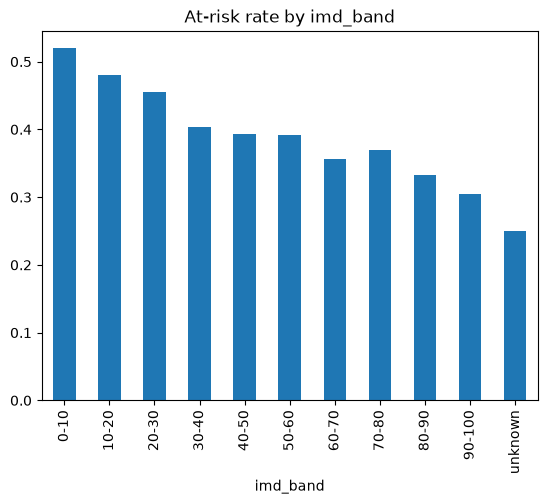

In [281]:
data.groupby("imd_band")["at_risk"].mean().plot(kind="bar")
plt.title("At-risk rate by imd_band")
plt.show()

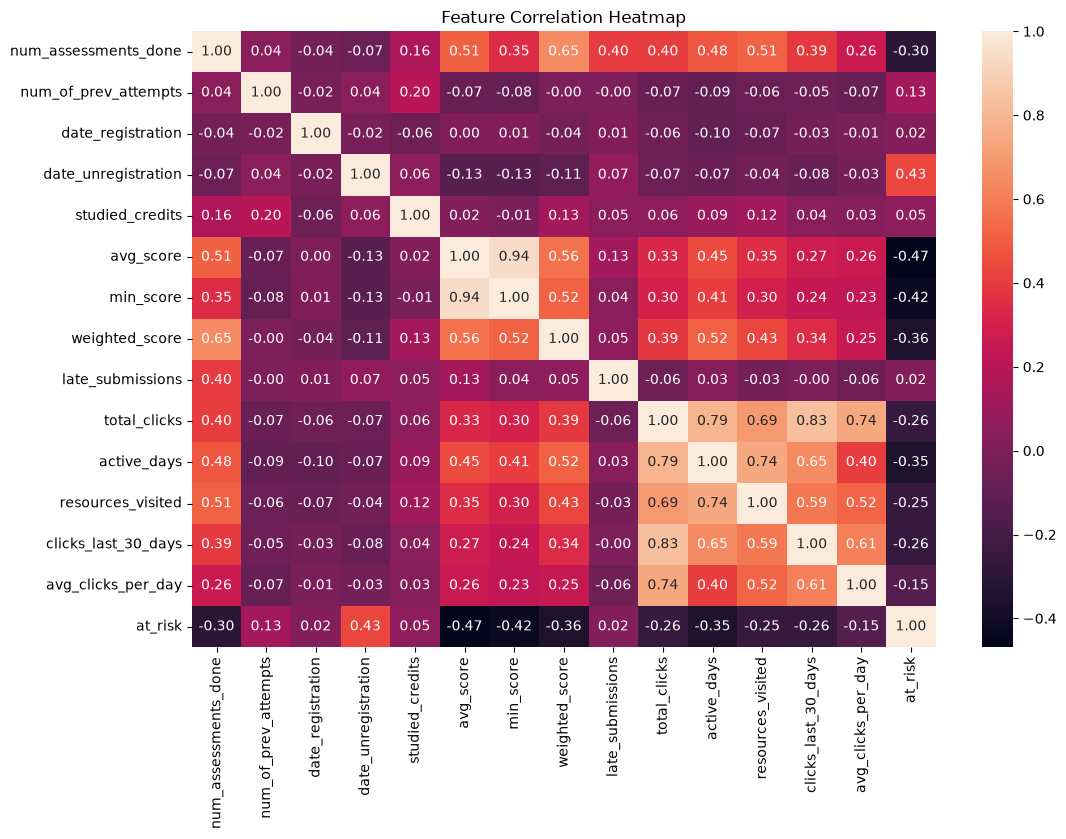

In [282]:
corr_matrix = data[num_feature_columns+['at_risk']].corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f')
plt.title("Feature Correlation Heatmap")
plt.show()

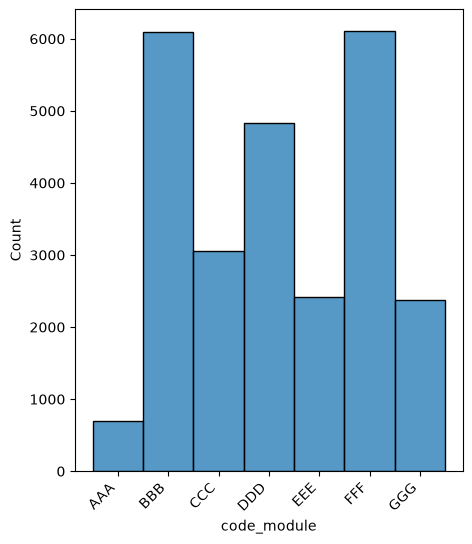

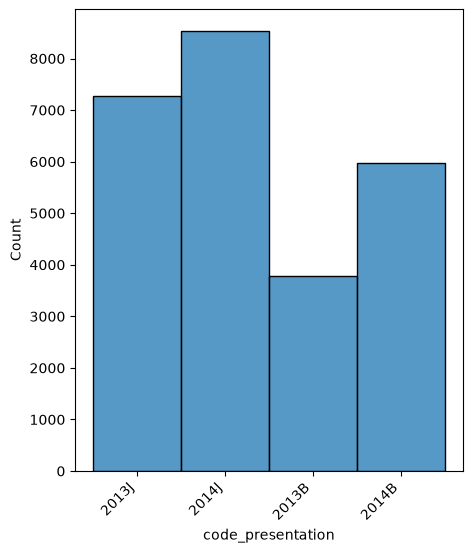

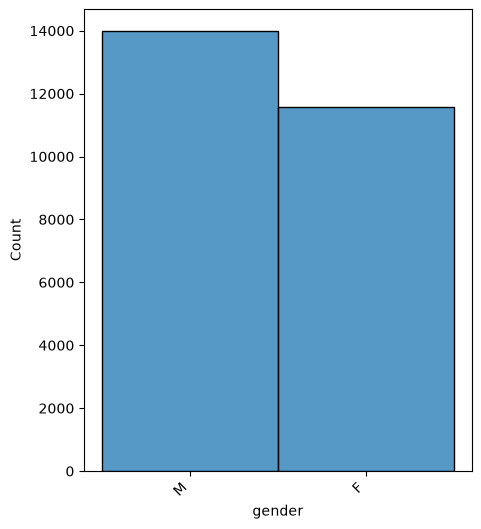

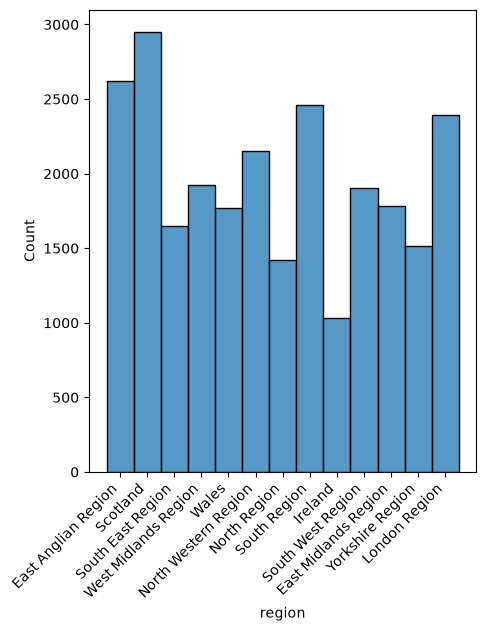

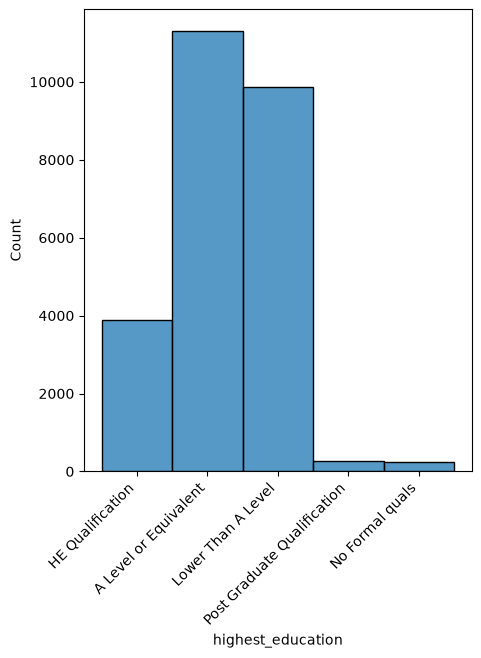

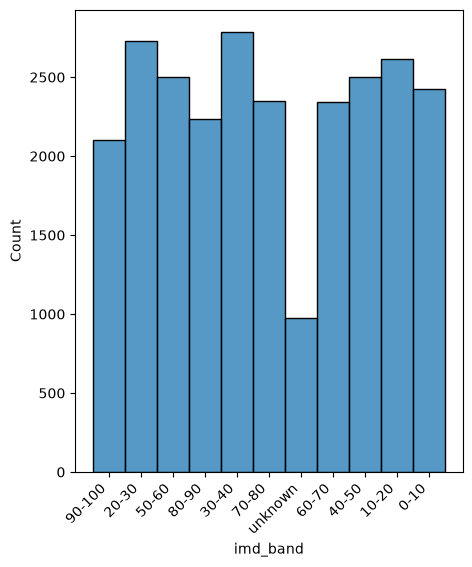

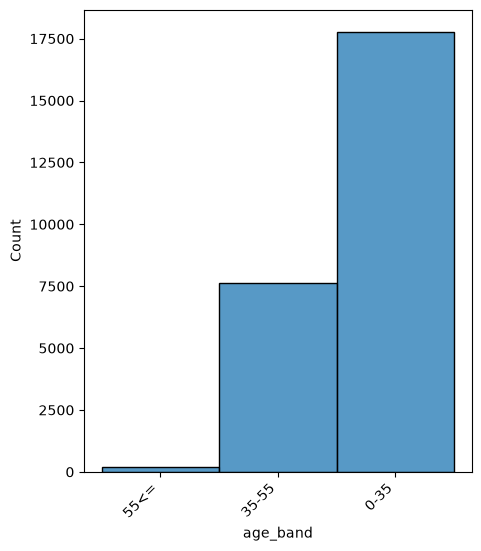

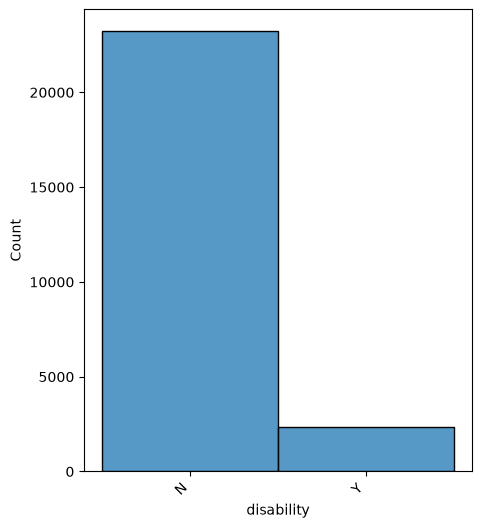

In [283]:
for i in cat_feature_columns:
    plt.figure(figsize=(5,6))
    plt.xticks(rotation=45,ha='right')
    sns.histplot(data[i])

- Avg_score vs at_risk (boxplot)

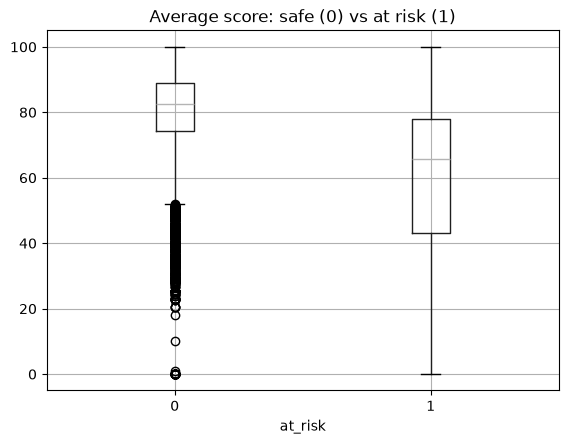

In [284]:
data.boxplot(column="avg_score", by="at_risk")
plt.title("Average score: safe (0) vs at risk (1)")
plt.suptitle("")
plt.show()

- total_clicks vs at_risk (boxplot)

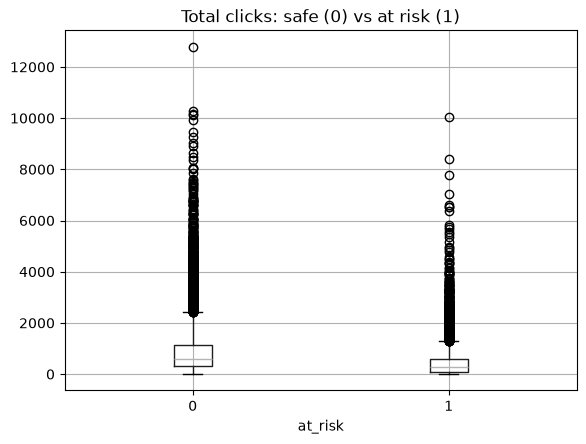

In [285]:
data.boxplot(column="total_clicks", by="at_risk")
plt.title("Total clicks: safe (0) vs at risk (1)")
plt.suptitle("")
plt.show()

- active_days vs at_risk

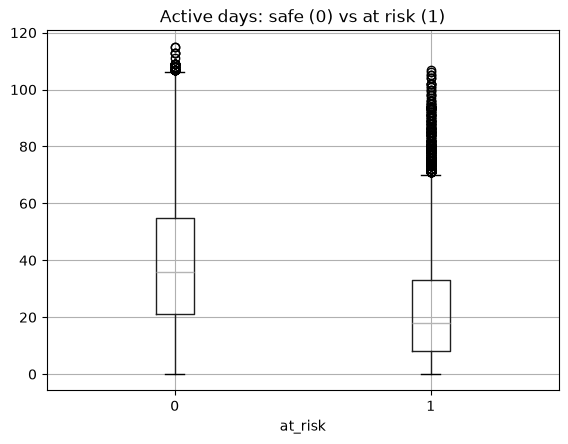

In [286]:
data.boxplot(column="active_days", by="at_risk")
plt.title("Active days: safe (0) vs at risk (1)")
plt.suptitle("")
plt.show()

- weighted_score vs at_risk

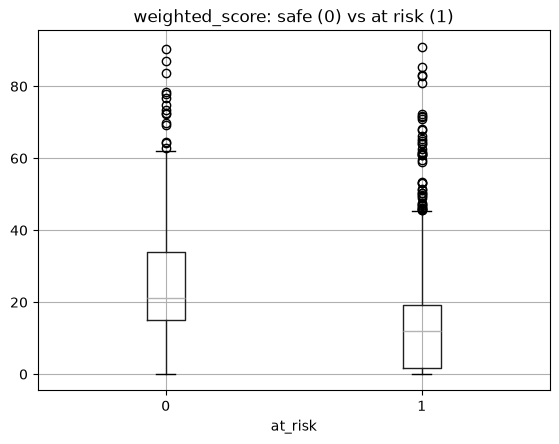

In [287]:
data.boxplot(column="weighted_score", by="at_risk")
plt.title("weighted_score: safe (0) vs at risk (1)")
plt.suptitle("")
plt.show()

- OutLiers

In [288]:
num_features = data[num_feature_columns].select_dtypes(include='number') #int64 or float64
Q1  = num_features.quantile(0.25)
Q3  = num_features.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (num_features < lower_bound) | (num_features > upper_bound)
print(outliers.sum())

num_assessments_done    4844
num_of_prev_attempts    3198
date_registration        372
date_unregistration     3041
studied_credits         1274
avg_score               2215
min_score               2622
weighted_score            32
late_submissions        1529
total_clicks            1754
active_days              262
resources_visited        882
clicks_last_30_days     2299
avg_clicks_per_day       981
dtype: int64


In [289]:
data["no_assessment"] = (data["num_assessments_done"] == 0).astype(int)

In [290]:
print(data["no_assessment"].value_counts())

no_assessment
0    23836
1     1726
Name: count, dtype: int64


In [291]:
num_feature_columns.append("no_assessment")
print(num_feature_columns)

['num_assessments_done', 'num_of_prev_attempts', 'date_registration', 'date_unregistration', 'studied_credits', 'avg_score', 'min_score', 'weighted_score', 'late_submissions', 'total_clicks', 'active_days', 'resources_visited', 'clicks_last_30_days', 'avg_clicks_per_day', 'no_assessment']


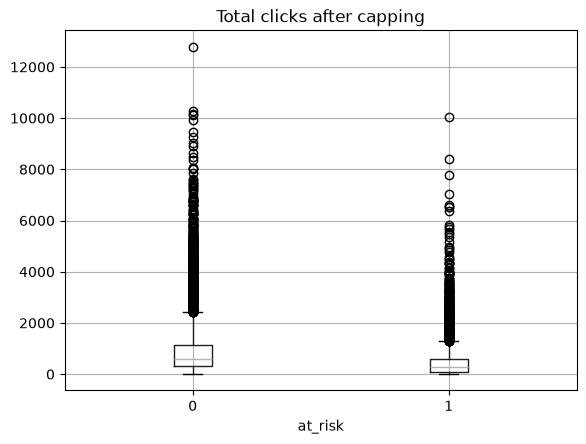

In [292]:
data.boxplot(column="total_clicks", by="at_risk")
plt.title("Total clicks after capping")
plt.suptitle("")
plt.show()

In [ ]:

df_encoded = pd.get_dummies(data,columns=cat_feature_columns,drop_first=True,dtype=int)
df_encoded=df_encoded.drop(['final_result','id_student','date_unregistration','has_unregistration'],axis=1)
print(df_encoded.dtypes)
print(df_encoded.shape)

num_of_prev_attempts                               int64
studied_credits                                    int64
at_risk                                            int64
date_registration                                float64
num_assessments_done                             float64
avg_score                                        float64
min_score                                        float64
weighted_score                                   float64
late_submissions                                 float64
total_clicks                                     float64
active_days                                      float64
resources_visited                                float64
clicks_last_30_days                              float64
avg_clicks_per_day                               float64
no_assessment                                      int64
code_module_BBB                                    int64
code_module_CCC                                    int64
code_module_DDD                

Index(['num_of_prev_attempts', 'studied_credits', 'at_risk',
       'date_registration', 'num_assessments_done', 'avg_score', 'min_score',
       'weighted_score', 'late_submissions', 'total_clicks', 'active_days',
       'resources_visited', 'clicks_last_30_days', 'avg_clicks_per_day',
       'no_assessment', 'code_module_BBB', 'code_module_CCC',
       'code_module_DDD', 'code_module_EEE', 'code_module_FFF',
       'code_module_GGG', 'code_presentation_2013J', 'code_presentation_2014B',
       'code_presentation_2014J', 'gender_M', 'region_East Midlands Region',
       'region_Ireland', 'region_London Region', 'region_North Region',
       'region_North Western Region', 'region_Scotland',
       'region_South East Region', 'region_South Region',
       'region_South West Region', 'region_Wales',
       'region_West Midlands Region', 'region_Yorkshire Region',
       'highest_education_HE Qualification',
       'highest_education_Lower Than A Level',
       'highest_education_No Forma

### 8. Choose X and Y

In [294]:

X = df_encoded.drop('at_risk',axis=1)
y = df_encoded["at_risk"]

In [295]:
print("X shape:", X.shape)
print("y shape:", y.shape)
X.sample(5)

X shape: (25562, 53)
y shape: (25562,)


,num_of_prev_attempts,studied_credits,date_registration,num_assessments_done,avg_score,min_score,weighted_score,late_submissions,total_clicks,active_days,...,imd_band_40-50,imd_band_50-60,imd_band_60-70,imd_band_70-80,imd_band_80-90,imd_band_90-100,imd_band_unknown,age_band_35-55,age_band_55<=,disability_Y
23809,0,30,-24.0,1.0,90.0,90.0,0.00,1.0,136.0,19.0,...,0,0,0,0,0,0,0,0,0,0
23651,0,30,-93.0,1.0,50.0,50.0,0.00,0.0,3.0,1.0,...,0,0,0,0,1,0,0,0,0,0
24469,0,30,-57.0,1.0,70.0,70.0,0.00,0.0,129.0,13.0,...,0,0,1,0,0,0,0,0,0,0
15225,0,60,-115.0,2.0,91.5,88.0,39.84,0.0,750.0,44.0,...,0,0,0,1,0,0,0,0,0,0
18650,0,90,-23.0,2.0,65.0,60.0,16.25,0.0,644.0,44.0,...,1,0,0,0,0,0,0,1,0,0


- Split into train and test
- Train set (80%)
- Test set (20%)
- stratify=y keeps the same ratio of at-risk students in both sets.

In [296]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, stratify=y, random_state=42)
print("Train rows:", len(X_train))
print("Test rows :", len(X_test))

Train rows: 20449
Test rows : 5113


- Upper Limit Capping 

In [297]:
cap_cols = ["total_clicks","clicks_last_30_days","resources_visited","avg_clicks_per_day"]
caps = X_train[cap_cols].quantile(0.99)
print("Upper limits:")
print(caps)

Upper limits:
total_clicks           4129.080000
clicks_last_30_days     948.000000
resources_visited       146.000000
avg_clicks_per_day       56.431039
Name: 0.99, dtype: float64


In [298]:
X_train = X_train.copy()
X_test = X_test.copy()
X_train[cap_cols] = X_train[cap_cols].clip(upper=caps, axis=1)
X_test[cap_cols] = X_test[cap_cols].clip(upper=caps, axis=1)

In [299]:
print("Training maximum values:")
print(X_train[cap_cols].max())
print("\nTest maximum values:")
print(X_test[cap_cols].max())
print("\nLearned upper limits:")
print(caps)

Training maximum values:
total_clicks           4129.080000
clicks_last_30_days     948.000000
resources_visited       146.000000
avg_clicks_per_day       56.431039
dtype: float64

Test maximum values:
total_clicks           4129.080000
clicks_last_30_days     948.000000
resources_visited       146.000000
avg_clicks_per_day       56.431039
dtype: float64

Learned upper limits:
total_clicks           4129.080000
clicks_last_30_days     948.000000
resources_visited       146.000000
avg_clicks_per_day       56.431039
Name: 0.99, dtype: float64


- Train Models

In [300]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

models = {
    "Logistic Regression": Pipeline([("scaler",StandardScaler()),
                                     ("model", LogisticRegression(max_iter=2000,random_state=42))]),
    "KNN": Pipeline([("scaler",StandardScaler()),
                     ("model",KNeighborsClassifier(n_neighbors=5))]),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
}

In [ ]:
from sklearn.model_selection import cross_val_score

results = []

for name, model in models.items():

    cv_f1 = cross_val_score(model, X_train,y_train,cv=5,scoring="f1", n_jobs=-1).mean()

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "CV_F1": cv_f1,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0)
        })

In [ ]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values("CV_F1", ascending=False)
display(results_df.round(4))

,Model,CV_F1,Accuracy,Precision,Recall,F1
3,Random Forest,0.7119,0.7901,0.8042,0.6252,0.7035
0,Logistic Regression,0.7046,0.7815,0.7730,0.6390,0.6997
2,Decision Tree,0.6802,0.7565,0.7251,0.6257,0.6718
1,KNN,0.5693,0.6992,0.6634,0.4966,0.5680


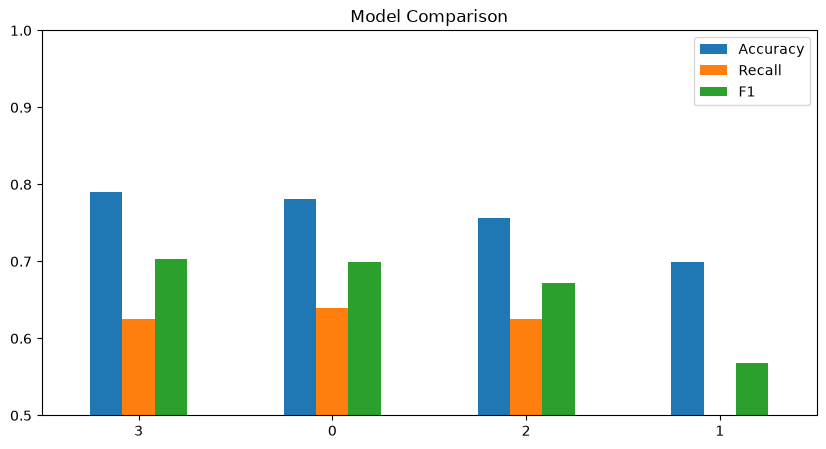

In [ ]:
results_df[["Accuracy", "Recall", "F1"]].plot(kind="bar", figsize=(10, 5))
plt.title("Model Comparison")
plt.ylim(0.5, 1)
plt.xticks(rotation=0)
plt.show()

- BEST Model

In [ ]:
best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]
print("Best model:", best_name)

Best model: Random Forest


In [ ]:
y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["Safe (0)", "At Risk (1)"]))

              precision    recall  f1-score   support

    Safe (0)       0.78      0.90      0.84      3077
 At Risk (1)       0.80      0.63      0.70      2036

    accuracy                           0.79      5113
   macro avg       0.79      0.76      0.77      5113
weighted avg       0.79      0.79      0.78      5113



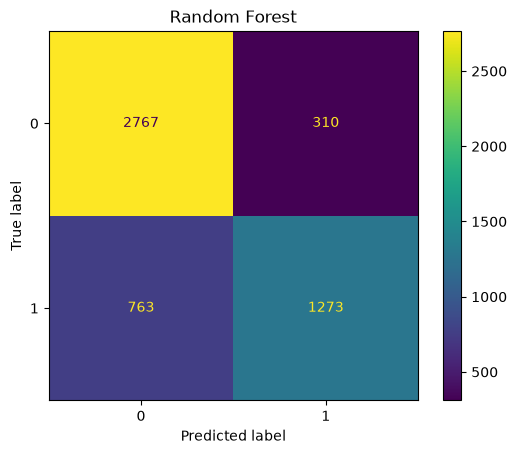

In [ ]:
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test)
plt.title(best_name)
plt.show()

- Cross Validation applying To compare Recall and F1 score

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=["recall", "f1"], n_jobs=-1)
    print(f"{name} | Recall: {scores['test_recall'].mean():.4f} | F1: {scores['test_f1'].mean():.4f}")

Logistic Regression | Recall: 0.6435 | F1: 0.7054
KNN | Recall: 0.4942 | F1: 0.5656
Decision Tree | Recall: 0.6184 | F1: 0.6816
Random Forest | Recall: 0.6450 | F1: 0.7155


In [ ]:
from sklearn.metrics import roc_auc_score
# Probability of At Risk (class 1)
test_probs = best_model.predict_proba(X_test)[:, 1]
# Calculate ROC-AUC
roc_auc = roc_auc_score(y_test, test_probs)
print("ROC-AUC Score:", round(roc_auc, 4))

ROC-AUC Score: 0.8552


- Testing On Different Threshold

- Hyperparameters Tuned in all Models

In [ ]:
from scipy.stats import randint
from sklearn.model_selection import RandomizedSearchCV

param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10, 100]},
    "KNN": {"model__n_neighbors": [3, 5, 7, 11, 15, 21]},
    "Decision Tree": {"max_depth": [3, 5, 7, 10, None],"min_samples_leaf": [1, 10, 30, 50]},
    "Random Forest": {"n_estimators": [100, 200, 300],"max_depth": [5, 10, 15, None],"min_samples_leaf": randint(1, 6),
                        "min_samples_split": randint(2, 11),
                        "max_features": ["sqrt", "log2"],"class_weight":["balanced","balanced_subsample"]}}

search = RandomizedSearchCV(
    estimator=best_model,
    param_distributions=param_grids[best_name],
    n_iter=10,
    cv=3,
    scoring="recall",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

search.fit(X_train, y_train)
tuned_model = search.best_estimator_
print("Best model:", best_name)
print("Best parameters:", search.best_params_)
print("Best CV recall:", round(search.best_score_, 4))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best model: Random Forest
Best parameters: {'class_weight': 'balanced', 'max_depth': 10, 'max_features': 'log2', 'min_samples_leaf': 4, 'min_samples_split': 8, 'n_estimators': 100}
Best CV recall: 0.7108


In [ ]:
from sklearn.model_selection import cross_val_predict
train_probs = cross_val_predict(tuned_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

In [ ]:

threshold_results = []
for threshold in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    predictions = (train_probs >= threshold).astype(int)
    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_train, predictions, zero_division=0),
        "Recall": recall_score(y_train, predictions, zero_division=0),
        "F1": f1_score(y_train, predictions, zero_division=0)
    })
threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(3))

,Threshold,Precision,Recall,F1
0,0.25,0.495,0.947,0.650
1,0.30,0.536,0.911,0.675
2,0.35,0.586,0.869,0.700
3,0.40,0.633,0.822,0.715
4,0.45,0.684,0.772,0.725
5,0.50,0.735,0.711,0.723


In [ ]:
chosen_threshold = 0.45

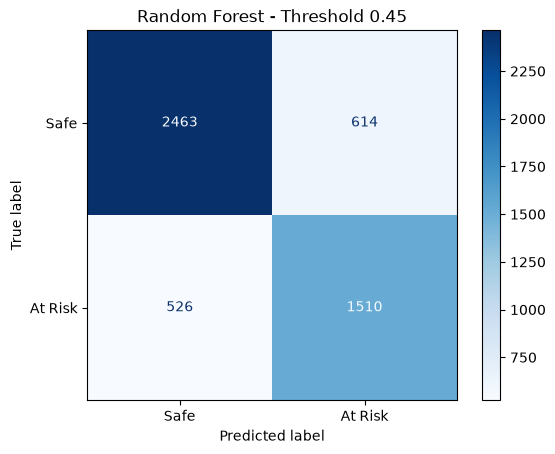

In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, final_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Safe","At Risk"])
disp.plot(cmap="Blues")
plt.title("Random Forest - Threshold 0.45")
plt.show()

In [ ]:
final_pred = (tuned_probs >= chosen_threshold).astype(int)
print(classification_report(y_test, final_pred, target_names=["Safe (0)", "At Risk (1)"]))

              precision    recall  f1-score   support

    Safe (0)       0.82      0.80      0.81      3077
 At Risk (1)       0.71      0.74      0.73      2036

    accuracy                           0.78      5113
   macro avg       0.77      0.77      0.77      5113
weighted avg       0.78      0.78      0.78      5113



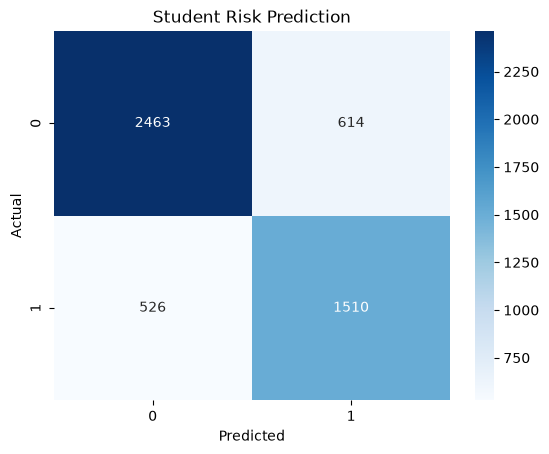

In [ ]:
y_pred = tuned_model.predict(X_test)
cm = confusion_matrix(y_test, final_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Student Risk Prediction")
plt.show()

- Feature importance

In [ ]:
importance = tuned_model.feature_importances_
feature_importance = pd.DataFrame({"Feature": X_train.columns,"Importance": importance})
feature_importance = feature_importance.sort_values(by="Importance",ascending=False)
print(feature_importance.head(15))

                                 Feature  Importance
4                              avg_score    0.162332
11                   clicks_last_30_days    0.142426
5                              min_score    0.136172
6                         weighted_score    0.120975
3                   num_assessments_done    0.058380
9                            active_days    0.058034
8                           total_clicks    0.050252
10                     resources_visited    0.038583
13                         no_assessment    0.034389
12                    avg_clicks_per_day    0.027686
19                       code_module_GGG    0.015986
37  highest_education_Lower Than A Level    0.015280
7                       late_submissions    0.015171
1                        studied_credits    0.013778
2                      date_registration    0.012044


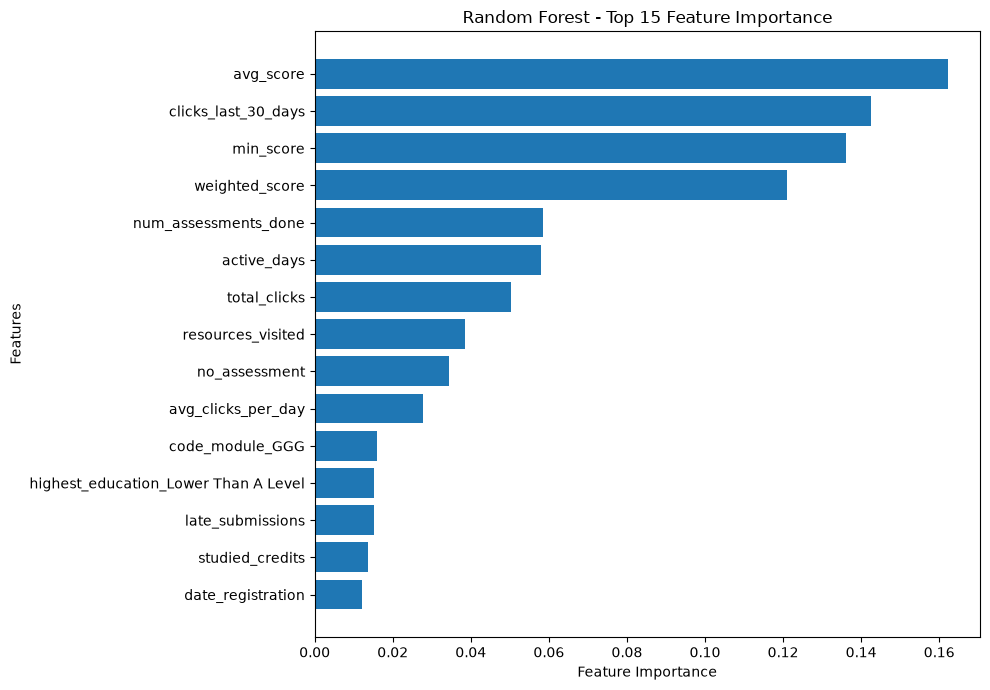

In [ ]:
top_features = feature_importance.head(15).sort_values(by="Importance")
plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"],top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Random Forest - Top 15 Feature Importance")
plt.tight_layout()
plt.show()

In [ ]:
import joblib
joblib.dump(tuned_model, "best_model.pkl")
print("Model saved")

Model saved
